# Predicting Major Arrival Delays for U.S. Domestic Flights
## ADS 505 Final Team Project, Team 10 Technical Notebook

- **Team:** Allen Ros, Christopher Guillen, Cameron Moran
- **Course:** ADS 505 Applied Data Science for Business, University of San Diego
- **GitHub repository:** https://github.com/aros-usd/ads-505-final-project

In [71]:
# import statements
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import mlba
from imblearn.over_sampling import SMOTE
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import precision_score, recall_score, roc_auc_score, roc_curve
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, StratifiedKFold, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier

# random seed constant
RANDOM_STATE = 123

# file location
DATA_FILE = 'Data/flights_sample_2025H1.csv'

# Section 1: Problem Statement and Data Description

**Problem:** About one in five U.S. domestic flights arrives late by 15 minutes or more. A delay costs the airline crew time, fuel, and other resources. This can cause further downstream effects like missed connections and later legs flown by the same aircraft. It can also increase overall terminal traffic and passenger dissatisfaction.

**Data Description:** The dataset was taken from the Bureau of Transportation Statistics (BTS). It has one row per non-stop domestic flight leg and 109 fields. We downloaded January through June of 2025 (~3.5 million flights) and sampled 5,000 flights from each month to create a manageable dataset for modeling. We also only selected a subset of 17 columns from the original 109 to reduce the dimensionality of the dataset and to avoid data leakage.

- The dataset was built by downloading the BTS monthly files for January through June of 2025 and using the `build_sample.py` script to create a random sample of 5,000 flights from each month, creating a 30,000-row dataset.
- Diverted and Cancelled flights were removed, as they have no arrival delay to predict
- 16 of the 17 columns are features and 1 is the target (ArrDel15).

**Objective:** Build and compare classification models that predict whether a scheduled domestic flight will arrive 15 or more minutes late (`ArrDel15 = 1`). The model should also identify which schedule characteristics are most associated with delay.

In [72]:
# load the dataset and view a few rows
flights_df = pd.read_csv(DATA_FILE)
print(f'Dataset shape: {flights_df.shape}')
flights_df.head()

Dataset shape: (30000, 17)


,Month,DayofMonth,DayOfWeek,FlightDate,Reporting_Airline,Origin,OriginState,Dest,DestState,CRSDepTime,DepTimeBlk,CRSArrTime,ArrDel15,ArrTimeBlk,CRSElapsedTime,Distance,DistanceGroup
0,1,1,3,2025-01-01,B6,JFK,NY,FLL,FL,501,0001-0559,804,0.0,0800-0859,183.0,1069.0,5
1,1,1,3,2025-01-01,AA,ORD,IL,CLT,NC,502,0001-0559,808,0.0,0800-0859,126.0,599.0,3
2,1,1,3,2025-01-01,OH,GRR,MI,DCA,VA,547,0001-0559,738,0.0,0700-0759,111.0,524.0,3
3,1,1,3,2025-01-01,WN,PDX,OR,DEN,CO,550,0001-0559,920,0.0,0900-0959,150.0,991.0,4
4,1,1,3,2025-01-01,AA,MSP,MN,MIA,FL,550,0001-0559,1103,0.0,1100-1159,253.0,1501.0,7


# Section 2: Exploratory Data Analysis

In [73]:
# start by separating the features and target variables
feature_cols = [
    "Month",
    "DayofMonth",
    "DayOfWeek",
    "FlightDate",
    "Reporting_Airline",
    "Origin",
    "Dest",
    "OriginState",
    "DestState",
    "CRSDepTime",
    "DepTimeBlk",
    "CRSArrTime",
    "ArrTimeBlk",
    "CRSElapsedTime",
    "Distance",
    "DistanceGroup",
]
target_col = [ 
    "ArrDel15"
]

*The 16 feature columns describe when a flight is scheduled (date, day, times), who operates it (airline), and where it flies (airports, states, distance). All of them are known before departure. ArrDel15 is the classification target.*

In [74]:
# check overall delay rate of dataset
delay_rate = flights_df['ArrDel15'].mean()
print(f'Overall delay rate: {delay_rate:.4f} ({delay_rate*100:.2f}%)')

Overall delay rate: 0.2191 (21.91%)


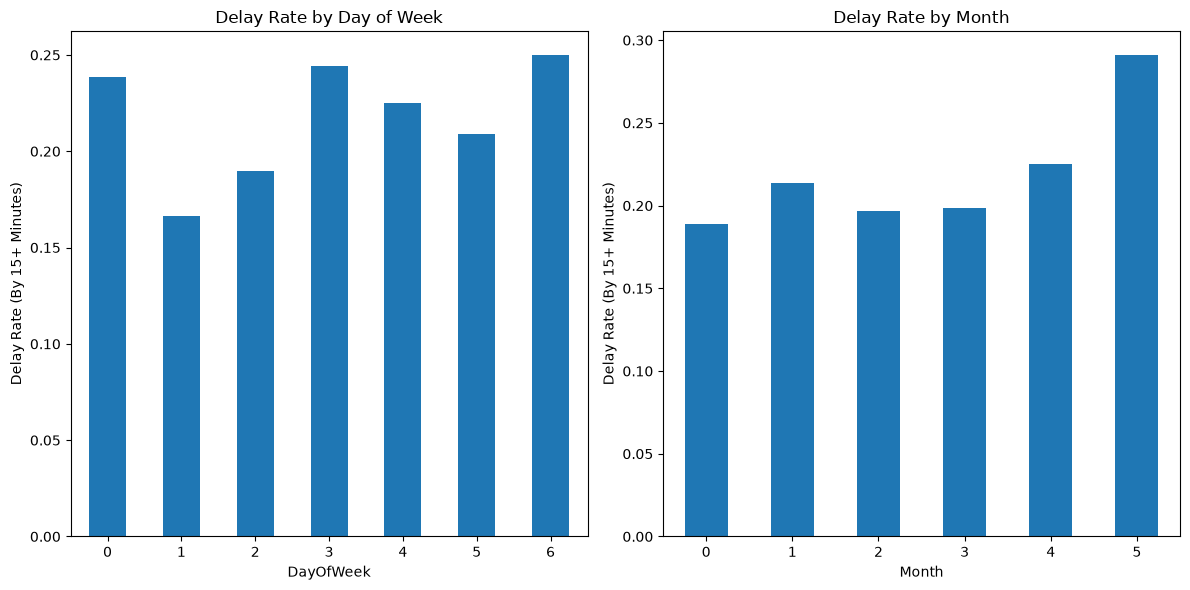

In [75]:
# delay rate by day of week and by month
delay_rate = flights_df['ArrDel15'].mean()
by_day = flights_df.groupby('DayOfWeek')['ArrDel15'].mean()
by_month = flights_df.groupby('Month')['ArrDel15'].mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for i, dataset in enumerate([by_day, by_month]):
    dataset.plot(kind='bar', ax=axes[i])
    axes[i].set_ylabel('Delay Rate (By 15+ Minutes)')
    axes[i].set_title(f'Delay Rate by {"Day of Week" if i == 0 else "Month"}')
    axes[i].set_xticklabels(axes[i].get_xticks(), rotation=0)


plt.tight_layout()
plt.show()

*The overall delay rate is ~21.9%. Tuesday (DayOfWeek = 1) is the best day in terms of lowest delay rates (~17%) and Sunday is the worst (~25%). This means there is a very present spread in delay rates across days. There is also a spread across months, with January having the lowest (~18%) and June having the highest (~29%).*

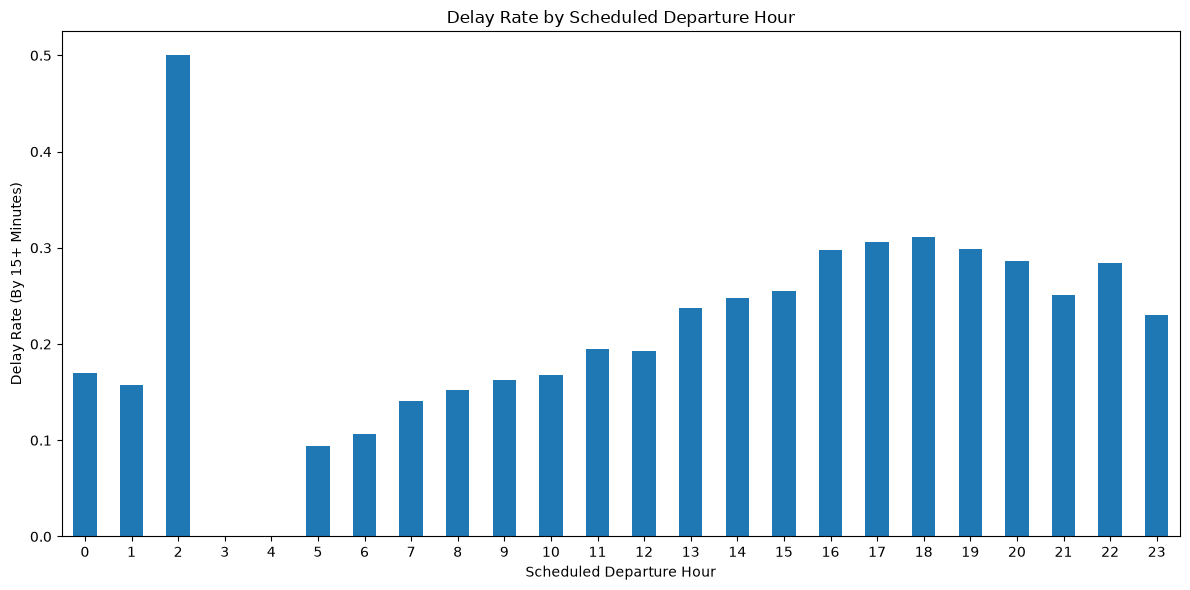

Flights per hour:
CRSDepTime
0       47
1       19
2        2
3        2
4        3
5      882
6     1993
7     2151
8     2077
9     1628
10    1786
11    1978
12    1727
13    1826
14    1788
15    1723
16    1835
17    1918
18    1829
19    1586
20    1354
21     977
22     647
23     222
Name: size, dtype: int64


In [76]:
# delay rate by scheduled departure time (CRSDepTime)
hours_df = flights_df.copy()
hours_df['CRSDepTime'] = hours_df['CRSDepTime'] // 100
hour_stats = hours_df.groupby('CRSDepTime')['ArrDel15'].agg(['mean', 'size'])

fig, ax = plt.subplots(figsize=(12, 6))
hour_stats['mean'].plot(kind='bar', ax=ax)
ax.set_xlabel('Scheduled Departure Hour')
ax.set_ylabel('Delay Rate (By 15+ Minutes)')
ax.set_title('Delay Rate by Scheduled Departure Hour')
ax.set_xticklabels(ax.get_xticks(), rotation=0)

plt.tight_layout()
plt.show()

# print flights per hour as support for the figure
print("Flights per hour:")
print(hour_stats['size'])

*Flights between 0 and 4 AM are very uncommon so their rates may be heavily skewed if any flights are delayed for those times in the sample. Ignoring these and looking strictly at the data from 5 AM onwards, we see a clear pattern. Flights leaving at 5-6 a.m. are delayed about 10% of the time, and the rate climbs steadily through the day to about 30% for 4-8 PM flights. This makes sense as delays early in the day can compound and propagate out to the flights that follow.*

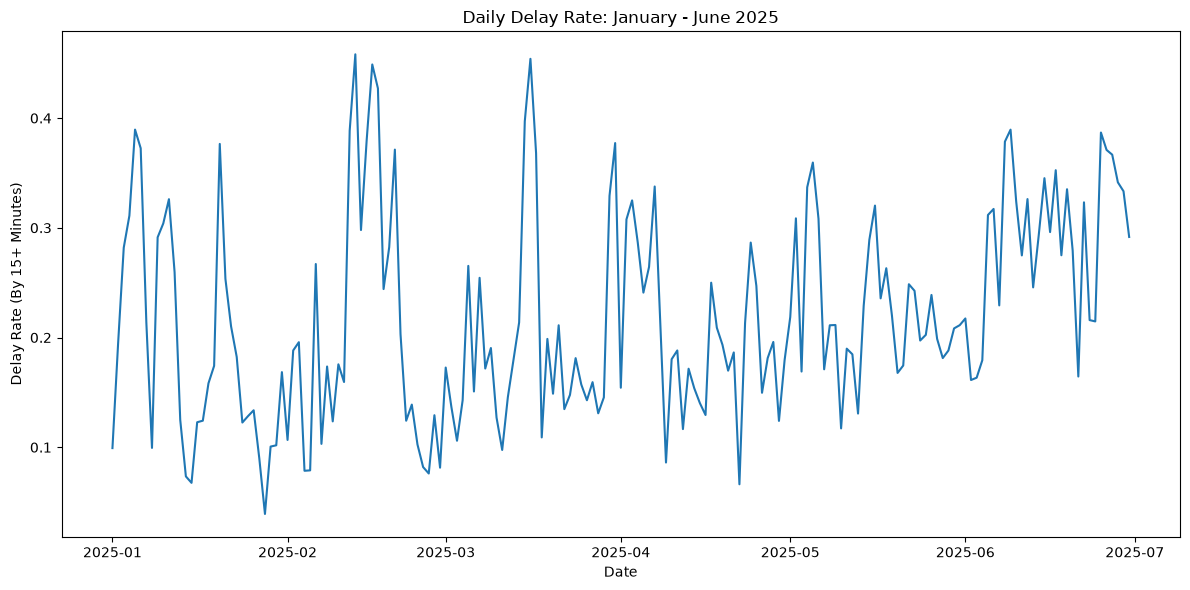

In [77]:
# delay rate by day
daily_rate = flights_df.groupby('FlightDate')['ArrDel15'].mean()
daily_rate.index = pd.to_datetime(daily_rate.index)

fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(daily_rate.index, daily_rate.values)
ax.set_title('Daily Delay Rate: January - June 2025')
ax.set_xlabel('Date')
ax.set_ylabel('Delay Rate (By 15+ Minutes)')

plt.tight_layout()
plt.show()

*The daily delay rate is very volatile. It ranges from  ~3-5% to ~45-47%. Fluctuations are likely caused by a variety of factors. Weather delays, aircraft issues, etc. can cause these delays. The goal is to understand underlying patterns and factors that contribute to these delays.*

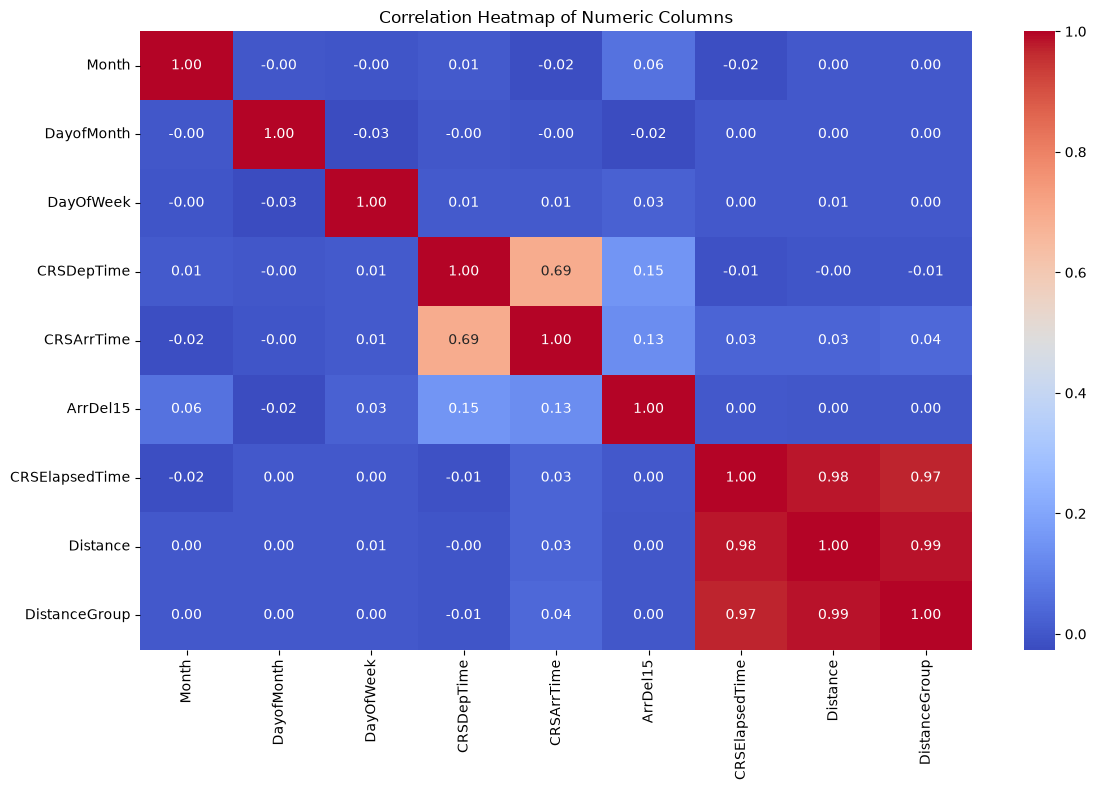

In [78]:
# correlation heatmap of the numeric features and targets
correlations = flights_df.select_dtypes(include='number').corr()

fig, ax = plt.subplots(figsize=(12, 8))
sns.heatmap(correlations, annot=True, fmt='.2f', cmap='coolwarm', ax=ax)
ax.set_title('Correlation Heatmap of Numeric Columns')

plt.tight_layout()
plt.show()


- *CRSElapsedTime, Distance, and DistanceGroup are almost perfectly correlated (about 0.97-0.99), because elapsed time is a function of distance. Keeping all three would result in multicollinearity, so Section 3 will handle this by dropping 1 or more of these columns.*

- *CRSDepTime and CRSArrTime are strongly correlated (about 0.68). A flight that departs later usually arrives later, but the correlation is not strong enough to warrant removing one or the other.*

- *The two target columns are strongly correlated with each other, which is to be expected. Every feature has only a weak  correlation with ArrDel15. This does not mean the features will be useless in predictions. The bar charts above show patterns (hour of day, month) that individual features alone cannot capture.*

# Section 3: Data Pre-Processing

In [79]:
# first step is to check for missing values in the dataset
flights_df.isnull().sum()

Month                0
DayofMonth           0
DayOfWeek            0
FlightDate           0
Reporting_Airline    0
Origin               0
OriginState          0
Dest                 0
DestState            0
CRSDepTime           0
DepTimeBlk           0
CRSArrTime           0
ArrDel15             0
ArrTimeBlk           0
CRSElapsedTime       0
Distance             0
DistanceGroup        0
dtype: int64

*No missing values, so no need for imputation or dropping rows.*

In [ ]:
# drop DistanceGroup and CRSElapsedTime due to high correlation with Distance and CRSElapsedTime
flights_df.drop(columns=['DistanceGroup', 'CRSElapsedTime'], inplace=True)

*Distance, DistanceGroup, and CRSElapsedTime are highly correlated, so we will keep only one of them. DistanceGroup and CRSElapsedTime are derived from Distance, so we will keep Distance and drop the other two.*

In [81]:
# feature engineering to create columns for weekend and holiday booleans
flights_df['FlightDate'] = pd.to_datetime(flights_df['FlightDate'])

# weekend flag (BTS codes DayOfWeek as Monday = 1 ... Sunday = 7)
flights_df['is_weekend'] = (flights_df['DayOfWeek'] >= 6).astype(int)

# add a holiday flag for flights within 3 days of a major US holiday
holidays = pd.to_datetime([
    '2025-01-01',  # New Year's Day
    '2025-01-20',  # Martin Luther King Jr. Day
    '2025-02-17',  # Presidents' Day
    '2025-04-20',  # Easter
    '2025-05-26',  # Memorial Day
    '2025-06-19',  # Juneteenth
])

def days_to_nearest_holiday(flight_date):
    return min(abs((flight_date - holiday).days) for holiday in holidays)

days_to_holiday = flights_df['FlightDate'].apply(days_to_nearest_holiday)
flights_df['is_holiday'] = (days_to_holiday <= 3).astype(int)

In [82]:
# convert departure and arrival times to hours for binning
# CRSDepTime and CRSArrTime are integers like 1836 so dividing by 100 gives the hour
flights_df['departure_hour'] = flights_df['CRSDepTime'] // 100
flights_df['arrival_hour'] = flights_df['CRSArrTime'] // 100

# drop the original time columns since they are no longer needed
flights_df.drop(columns=['CRSDepTime', 'CRSArrTime', 'DepTimeBlk', 'ArrTimeBlk'], inplace=True)

In [83]:
# check for outliers by Distance and CRSElapsedTime using IQR method
for col in ['Distance', 'CRSElapsedTime']:
    q1 = flights_df[col].quantile(0.25)
    q3 = flights_df[col].quantile(0.75)
    iqr = q3 - q1
    n_out = ((flights_df[col] < q1 - 1.5 * iqr) | (flights_df[col] > q3 + 1.5 * iqr)).sum()
    print(f'{col}: {n_out} outliers ({n_out / len(flights_df):.1%})')

# print 10 outliers for each column
for col in ['Distance', 'CRSElapsedTime']:
    q1 = flights_df[col].quantile(0.25)
    q3 = flights_df[col].quantile(0.75)
    iqr = q3 - q1
    outliers = flights_df[(flights_df[col] < q1 - 1.5 * iqr) | (flights_df[col] > q3 + 1.5 * iqr)]
    print(f'\n{col} outliers:')
    print(outliers[['OriginState', 'DestState', col, 'ArrDel15']].head(10))
    

Distance: 1714 outliers (5.7%)
CRSElapsedTime: 1554 outliers (5.2%)

Distance outliers:
    OriginState DestState  Distance  ArrDel15
12           CA        NY    2475.0       0.0
19           CA        NC    2296.0       0.0
38           CA        HI    2367.0       0.0
57           NJ        NV    2227.0       0.0
65           NY        CA    2475.0       0.0
71           CA        HI    2615.0       0.0
97           NV        HI    2762.0       0.0
148          CA        MA    2704.0       0.0
158          WA        FL    2717.0       1.0
160          CA        VA    2253.0       1.0

CRSElapsedTime outliers:
   OriginState DestState  CRSElapsedTime  ArrDel15
12          CA        NY           324.0       0.0
26          FL        AZ           311.0       0.0
28          PR        IL           319.0       0.0
38          CA        HI           345.0       0.0
46          VA        AZ           328.0       0.0
57          NJ        NV           340.0       0.0
62          MI        C

*The outliers in Distance and CRSElapsedTime do not seem to be errors, they just seem to be longer flights (Ex: CA to NY or CA to HI). These will not be removed because they are valid flights and any model should be able to handle them.*

In [84]:
# state columns are also not necessary because the airport columns already capture the information
# they were just retained to this point for the above outlier analysis, but they can be dropped now
flights_df.drop(columns=['OriginState', 'DestState'], inplace=True)

# also drop FlightDate and DayofMonth because models should not be able to use them to generalize to future flights
flights_df.drop(columns=['FlightDate', 'DayofMonth'], inplace=True)

In [ ]:
# finalize feature cols and make a new model_df copy
feature_cols = [
    "Month",
    "DayOfWeek",
    "Reporting_Airline",
    "Origin",
    "Dest",
    "Distance",
    # engineered features
    "is_weekend",
    "is_holiday",
    "departure_hour",
    "arrival_hour",
]
model_df = flights_df[feature_cols + target_col].copy()
print(f'Model dataset shape: {model_df.shape}')

Model dataset shape: (30000, 12)


In [ ]:
# use one-hot encoding for categorical features and standard scaling for numeric features
categorical_features = [
    'Month',
    'DayOfWeek',
    'Reporting_Airline',
    'Origin',
    'Dest'
]
numeric_features = [
    'Distance',
    'departure_hour',
    'arrival_hour'
]
binary_features = [
    'is_weekend',
    'is_holiday'
]
oce = OneHotEncoder(sparse_output=False, handle_unknown='ignore')
scaler = StandardScaler()

# combine the steps into one preprocessor, binary features pass through unchanged
# it is only defined here and will be used in section 4
preprocessor = ColumnTransformer([
    ('categorical', oce, categorical_features),
    ('numeric', scaler, numeric_features),
    ('binary', 'passthrough', binary_features),
])

# Section 4: Data Splitting

In [92]:
# separate predictors and target (target_col is a list, so take the single column as a Series)
x = model_df[feature_cols]
y = model_df[target_col[0]]

# stratified 60/20/20 split (train, test, validation)
# you can't split in one step, so split twice (once into 60/40, then split the 40 into 20/20)
x_train, x_temp, y_train, y_temp = train_test_split(x, y, train_size=0.6, stratify=y, random_state=RANDOM_STATE)
x_valid, x_test, y_valid, y_test = train_test_split(x_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=RANDOM_STATE)

# confirm the sizes and that the delay rate is the same in every set
for name, target in [('Train', y_train), ('Validation', y_valid), ('Test', y_test)]:
    print(f'{name} rows = {len(target)}, Delay Rate = {target.mean():.1%}')

Train rows = 18000, Delay Rate = 21.9%
Validation rows = 6000, Delay Rate = 21.9%
Test rows = 6000, Delay Rate = 21.9%


In [94]:
# fit learns the data and transform applied the learned transformation to the data
# we only want to fit on the training data, then apply the same transformation to the validation and test data
# this is because learning the scaling or one-hot encoding from the validation or test data would be a form of data leakage 
x_train_prepared = preprocessor.fit_transform(x_train)
x_valid_prepared = preprocessor.transform(x_valid)
x_test_prepared = preprocessor.transform(x_test)
print(f'Encoded Shapes:')
print(f'Train {x_train_prepared.shape}')
print(f'Validation {x_valid_prepared.shape}')
print(f'Test {x_test_prepared.shape}')

Encoded Shapes:
Train (18000, 659)
Validation (6000, 659)
Test (6000, 659)


# Section 5: Model Building Strategy

# Section 6: Model Performance and Hyperparameter Tuning

# Section 7: Results and Final Model Selection

# Section 8: Discussion and Conclusion